<a href="https://colab.research.google.com/github/mauryaswasti8-droid/Ascendra/blob/main/ibl_bwm_explore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q dandi pynwb h5py remfile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 431.5/431.5 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.2/194.2 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.0/122.0 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.6/366.6 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.9/86.9 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 284.1/284.1 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.6/41.6 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.7/1

In [2]:
from dandi.dandiapi import DandiAPIClient
import pynwb, h5py, remfile

client = DandiAPIClient()
dandiset = client.get_dandiset("000409", "0.260309.1324")
path = "sub-CSH-ZAD-001/sub-CSH-ZAD-001_ses-3e7ae7c0-fe8b-487c-9354-036236fa1010_desc-processed_behavior+ecephys.nwb"
asset = dandiset.get_asset_by_path(path)
url = asset.get_content_url(follow_redirects=1, strip_query=True)

f = h5py.File(remfile.File(url), "r")
io = pynwb.NWBHDF5IO(file=f, load_namespaces=True)
nwb = io.read()
print(nwb)

root pynwb.file.NWBFile at 0x136656485034240
Fields:
  devices: {
    Probe00 <class 'pynwb.device.Device'>
  }
  electrode_groups: {
    Probe00 <class 'pynwb.ecephys.ElectrodeGroup'>
  }
  electrodes: electrodes <class 'pynwb.ecephys.ElectrodesTable'>
  file_create_date: [datetime.datetime(2026, 3, 3, 10, 18, 0, 951942, tzinfo=tzlocal())]
  identifier: 15a9c6eb-d2ac-4d49-ac7b-936c1fe3cb39
  institution: Cold Spring Harbor Laboratory
  intervals: {
    trials <class 'pynwb.epoch.TimeIntervals'>
  }
  lab: zadorlab
  lab_meta_data: {
    ibl_metadata <class 'abc.IblMetadata'>,
    ibl_probe_insertion_trajectories <class 'abc.IblProbeInsertionTrajectories'>,
    localization <class 'abc.Localization'>
  }
  processing: {
    lick_times <class 'pynwb.base.ProcessingModule'>,
    wheel <class 'pynwb.base.ProcessingModule'>
  }
  protocol: _iblrig_tasks_ephysChoiceWorld6.2.5
  session_description: 
  session_id: 3e7ae7c0-fe8b-487c-9354-036236fa1010
  session_start_time: 2020-01-16 15:53:21

In [4]:
print(list(nwb.acquisition.keys()))
print(list(nwb.processing.keys()))
print(list(nwb.intervals.keys()))
print(nwb.units.colnames)

[]
['lick_times', 'wheel']
['trials']
('unit_name', 'electrodes', 'max_electrode', 'max_spike_amplitude_uV', 'probe_name', 'spike_amplitude_std_dB', 'spike_times', 'ibl_quality_score', 'rp_violation', 'spike_amplitudes_uV', 'missed_spikes_estimate', 'firing_rate', 'cluster_uuid', 'waveform_mean', 'cumulative_drift_um_per_hour', 'sliding_rp_violation', 'peak_to_trough_duration_ms', 'kilosort2_label', 'spike_count', 'isi_violations_ratio', 'distance_from_probe_tip_um', 'presence_ratio_std', 'presence_ratio', 'noise_cutoff', 'spike_distances_from_probe_tip_um', 'min_spike_amplitude_uV', 'median_spike_amplitude_uV')


In [5]:
trials = nwb.intervals["trials"].to_dataframe()
print(trials.columns.tolist())
trials.head()

['start_time', 'stop_time', 'quiescence_period', 'gabor_stimulus_onset_time', 'auditory_cue_time', 'wheel_movement_onset_time', 'choice_registration_time', 'feedback_time', 'gabor_stimulus_offset_time', 'gabor_stimulus_contrast', 'gabor_stimulus_side', 'mouse_wheel_choice', 'is_mouse_rewarded', 'reward_volume_uL', 'probability_left', 'block_type', 'block_index']


,start_time,stop_time,quiescence_period,gabor_stimulus_onset_time,auditory_cue_time,wheel_movement_onset_time,choice_registration_time,feedback_time,gabor_stimulus_offset_time,gabor_stimulus_contrast,gabor_stimulus_side,mouse_wheel_choice,is_mouse_rewarded,reward_volume_uL,probability_left,block_type,block_index
id,,,,,,,,,,,,,,,,,
0,89.422024,92.274432,0.545003,90.157550,90.068459,90.50599,90.701327,90.701429,91.774322,25.00,right,counter_clockwise,True,1.5,0.5,unbiased,0
1,92.666332,96.874214,0.467914,94.773188,94.774055,94.87999,95.307320,95.307402,96.374128,100.00,left,clockwise,True,1.5,0.5,unbiased,0
2,97.222010,101.707428,0.615546,99.789720,99.790687,99.89699,100.138420,100.138518,101.207345,100.00,left,clockwise,True,1.5,0.5,unbiased,0
3,102.055827,105.739622,0.604984,103.806118,103.806952,103.95599,104.184523,104.184614,105.239542,100.00,right,counter_clockwise,True,1.5,0.5,unbiased,0
4,106.131419,110.322831,0.654852,107.324000,107.324900,107.22799,107.767323,107.767889,109.822783,6.25,right,clockwise,False,0.0,0.5,unbiased,0


In [6]:
print(len(trials))
print(trials["block_type"].value_counts())
print(trials.groupby("block_index")["probability_left"].agg(["first", "count"]))
print(trials["mouse_wheel_choice"].value_counts(dropna=False))

854
block_type
left_block     401
right_block    363
unbiased        90
Name: count, dtype: int64
             first  count
block_index              
0              0.5     90
1              0.2     51
2              0.8     66
3              0.2     49
4              0.8     38
5              0.2     61
6              0.8     62
7              0.2     27
8              0.8     71
9              0.2     99
10             0.8     65
11             0.2     47
12             0.8     96
13             0.2     29
14             0.8      3
mouse_wheel_choice
clockwise            473
counter_clockwise    377
none                   4
Name: count, dtype: int64


In [7]:
print(nwb.electrodes.colnames)
el = nwb.electrodes.to_dataframe()
el.head()

('location', 'group', 'electrode_name', 'contact_shapes', 'channel_name', 'rel_x', 'rel_y', 'probe_name', 'contact_ids', 'shank_ids', 'adc_group', 'adc_sample_order', 'group_name', 'x', 'y', 'z', 'imp', 'filtering')


,location,group,electrode_name,contact_shapes,channel_name,rel_x,rel_y,probe_name,contact_ids,shank_ids,adc_group,adc_sample_order,group_name,x,y,z,imp,filtering
id,,,,,,,,,,,,,,,,,,
0,void,Probe00 pynwb.ecephys.ElectrodeGroup at 0x1366...,e0,square,"AP0,LF0",16.0,0.0,Probe00,e0,,0,0,Probe00,8050.0,6182.0,4363.0,NaN,
1,void,Probe00 pynwb.ecephys.ElectrodeGroup at 0x1366...,e1,square,"AP1,LF1",48.0,0.0,Probe00,e1,,1,0,Probe00,8050.0,6182.0,4363.0,NaN,
2,void,Probe00 pynwb.ecephys.ElectrodeGroup at 0x1366...,e2,square,"AP2,LF2",0.0,20.0,Probe00,e2,,0,1,Probe00,8050.0,6165.0,4373.0,NaN,
3,void,Probe00 pynwb.ecephys.ElectrodeGroup at 0x1366...,e3,square,"AP3,LF3",32.0,20.0,Probe00,e3,,1,1,Probe00,8050.0,6165.0,4373.0,NaN,
4,root,Probe00 pynwb.ecephys.ElectrodeGroup at 0x1366...,e4,square,"AP4,LF4",16.0,40.0,Probe00,e4,,0,2,Probe00,8050.0,6149.0,4384.0,NaN,


In [8]:
units = nwb.units.to_dataframe()
print(len(units))
units[["max_electrode", "ibl_quality_score", "firing_rate", "spike_count"]].head()

519


,max_electrode,ibl_quality_score,firing_rate,spike_count
id,,,,
0,location ...,0.666667,15.406116,83465
1,location ...,0.333333,5.631774,30511
2,location ...,0.000000,15.779709,85489
3,location ...,0.333333,17.335734,93919
4,location ...,0.000000,13.176184,71384


In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

df = trials.copy()
df = df[df["mouse_wheel_choice"].isin(["clockwise", "counter_clockwise"])]

# sanity check: on rewarded trials, side and choice should line up perfectly
print(pd.crosstab(df.loc[df.is_mouse_rewarded == True, "gabor_stimulus_side"],
                  df.loc[df.is_mouse_rewarded == True, "mouse_wheel_choice"]))

mouse_wheel_choice   clockwise  counter_clockwise
gabor_stimulus_side                              
left                       410                  0
right                        0                336


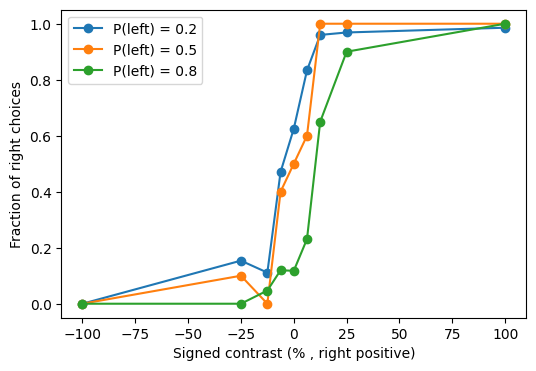

In [10]:
df["signed_contrast"] = np.where(df["gabor_stimulus_side"] == "left", -1, 1) * df["gabor_stimulus_contrast"]
df["chose_right"] = (df["mouse_wheel_choice"] == "counter_clockwise").astype(int)

plt.figure(figsize=(6, 4))
for p, g in df.groupby("probability_left"):
    curve = g.groupby("signed_contrast")["chose_right"].mean()
    plt.plot(curve.index, curve.values, marker="o", label=f"P(left) = {p}")
plt.xlabel("Signed contrast (% , right positive)")
plt.ylabel("Fraction of right choices")
plt.legend()
plt.show()

In [11]:
counts = df.groupby(["probability_left", "signed_contrast"]).size().unstack(0)
print(counts)

probability_left  0.2  0.5  0.8
signed_contrast                
-100.00            21   10   63
-25.00             13   10   75
-12.50             18   10   85
-6.25              17   10   67
 0.00              40   10   51
 6.25              66   10   13
 12.50             50   10   20
 25.00             64   10   10
 100.00            70   10   17


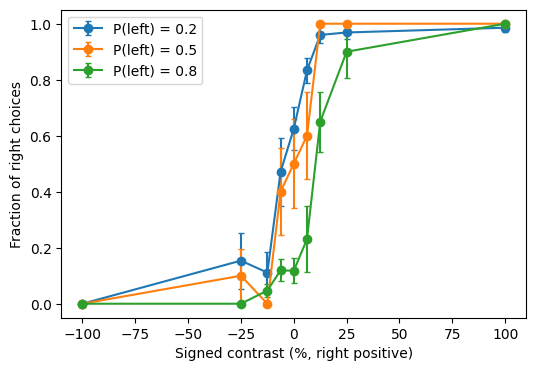

In [12]:
plt.figure(figsize=(6, 4))
for p, g in df.groupby("probability_left"):
    s = g.groupby("signed_contrast")["chose_right"].agg(["mean", "count"])
    se = np.sqrt(s["mean"] * (1 - s["mean"]) / s["count"])
    plt.errorbar(s.index, s["mean"], yerr=se, marker="o", capsize=2, label=f"P(left) = {p}")
plt.xlabel("Signed contrast (%, right positive)")
plt.ylabel("Fraction of right choices")
plt.legend()
plt.show()

In [13]:
print(type(units["max_electrode"].iloc[0]))

<class 'pandas.core.frame.DataFrame'>


In [14]:
units["region"] = units["max_electrode"].apply(lambda x: x["location"].iloc[0])
print(units["region"].value_counts())

good = units[units["ibl_quality_score"] >= 0.99]
print(len(good))
print(good["region"].value_counts())

region
Midbrain                                        225
Precommissural nucleus                           53
Midbrain reticular nucleus                       47
Fields of Forel                                  37
Substantia nigra reticular part                  28
cerebal peduncle                                 27
Ventral tegmental area                           25
Subparafascicular nucleus parvicellular part     20
Substantia nigra compact part                    18
root                                             16
posterior commissure                              7
void                                              5
choroid plexus                                    4
Thalamus                                          3
habenular commissure                              3
third ventricle                                   1
Name: count, dtype: int64
50
region
Midbrain                                        18
Fields of Forel                                  6
Substantia nigra reticu

In [15]:
good = units[units["ibl_quality_score"] >= 0.99].copy()

tr = trials.copy()
tr = tr[tr["gabor_stimulus_onset_time"].notna()]
tr = tr[tr["probability_left"] != 0.5]          # drop the unbiased block
tr = tr[tr["block_index"] != tr["block_index"].max()]  # drop the 3-trial last block

t0 = tr["gabor_stimulus_onset_time"].values
win = (-0.6, -0.1)  # seconds relative to stimulus onset

X = np.array([[np.sum((st >= t + win[0]) & (st < t + win[1])) for st in good["spike_times"]]
              for t in t0])
y = (tr["probability_left"].values == 0.8).astype(int)
groups = tr["block_index"].values
print(X.shape, y.mean())

(761, 50) 0.5229960578186597


In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score

clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
scores = cross_val_score(clf, X, y, groups=groups, cv=GroupKFold(n_splits=5))
print(scores, scores.mean(), "majority baseline:", max(y.mean(), 1 - y.mean()))

[0.15753425 0.3862069  0.25       0.22435897 0.64285714] 0.33219145206863676 majority baseline: 0.5229960578186597


In [17]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

clf = make_pipeline(StandardScaler(),
                    LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced"))
cv = GroupKFold(n_splits=5)

# class mix of each test fold, to see the imbalance directly
for i, (tr_i, te_i) in enumerate(cv.split(X, y, groups)):
    print(i, "test frac class 1:", round(y[te_i].mean(), 2), "n =", len(te_i))

proba = cross_val_predict(clf, X, y, groups=groups, cv=cv, method="predict_proba")[:, 1]
print("balanced acc:", balanced_accuracy_score(y, proba > 0.5))
print("AUC:", roc_auc_score(y, proba))

0 test frac class 1: 0.0 n = 146
1 test frac class 1: 0.66 n = 145
2 test frac class 1: 0.68 n = 160
3 test frac class 1: 0.42 n = 156
4 test frac class 1: 0.82 n = 154
balanced acc: 0.37520938023450584
AUC: 0.3005108185555878


In [18]:
from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.metrics import roc_auc_score

def pseudo_blocks(n_trials, rng):
    labels = [0.5] * 90
    side = rng.choice([0.2, 0.8])
    while len(labels) < n_trials:
        L = int(rng.exponential(60))
        while not (20 <= L <= 100):
            L = int(rng.exponential(60))
        labels += [side] * L
        side = 0.8 if side == 0.2 else 0.2
    return np.array(labels[:n_trials])

def decode_auc(X, y):
    folds = np.arange(len(y)) % 5   # interleaved folds
    clf = make_pipeline(StandardScaler(),
                        LogisticRegression(penalty="l1", solver="liblinear", C=0.1))
    p = cross_val_predict(clf, X, y, cv=PredefinedSplit(folds), method="predict_proba")[:, 1]
    return roc_auc_score(y, p)

idx = tr.index.values            # positions of the trials in X
real = decode_auc(X, y)

rng = np.random.default_rng(0)
null = []
for _ in range(200):
    pl = pseudo_blocks(len(trials), rng)[idx]
    yp = (pl == 0.8).astype(int)
    if yp.min() == yp.max():
        continue
    null.append(decode_auc(X, yp))
null = np.array(null)

print("real AUC:", round(real, 3))
print("null median:", np.median(null).round(3), "| 95th percentile:", np.percentile(null, 95).round(3))
print("p ~", (np.sum(null >= real) + 1) / (len(null) + 1))

real AUC: 0.754
null median: 0.653 | 95th percentile: 0.722
p ~ 0.004975124378109453


In [19]:

# Audit trial-index alignment. This does NOT rerun the decoder.

print("Original trials:")
print("  rows:", len(trials))
print("  index min/max:", trials.index.min(), trials.index.max())
print("  index unique:", trials.index.is_unique)
print("  index monotonic:", trials.index.is_monotonic_increasing)

print("\nFiltered trials (tr):")
print("  rows:", len(tr))
print("  index min/max:", tr.index.min(), tr.index.max())
print("  index unique:", tr.index.is_unique)
print("  index monotonic:", tr.index.is_monotonic_increasing)

idx = tr.index.to_numpy()

print("\nAlignment checks:")
print("  All filtered IDs exist in original index:",
      tr.index.isin(trials.index).all())
print("  All IDs valid as positions in pseudo-label array:",
      np.all((idx >= 0) & (idx < len(trials))))

# Compare the retained rows to the original table in the same order.
same_order = np.array_equal(
    tr.index.to_numpy(),
    trials.loc[tr.index].index.to_numpy()
)
print("  Filtered rows preserve original index order:", same_order)

# Check whether the original index labels equal positional row numbers.
print("  Original index equals 0..N-1:",
      np.array_equal(trials.index.to_numpy(), np.arange(len(trials))))

# Show retained rows around the first and last few positions.
print("\nFirst retained trial IDs:", idx[:10])
print("Last retained trial IDs:", idx[-10:])
print("First retained prior labels:", tr["probability_left"].to_numpy()[:10])
print("Last retained prior labels:", tr["probability_left"].to_numpy()[-10:])


Original trials:
  rows: 854
  index min/max: 0 853
  index unique: True
  index monotonic: True

Filtered trials (tr):
  rows: 761
  index min/max: 90 850
  index unique: True
  index monotonic: True

Alignment checks:
  All filtered IDs exist in original index: True
  All IDs valid as positions in pseudo-label array: True
  Filtered rows preserve original index order: True
  Original index equals 0..N-1: True

First retained trial IDs: [90 91 92 93 94 95 96 97 98 99]
Last retained trial IDs: [841 842 843 844 845 846 847 848 849 850]
First retained prior labels: [0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2]
Last retained prior labels: [0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2 0.2]


In [20]:

# Compare the actual retained block structure with the pseudo-block generator.

import numpy as np
import pandas as pd

# Actual blocks in the retained dataset
real_blocks = (
    tr.groupby("block_index", sort=True)
      .agg(
          prior=("probability_left", "first"),
          n_trials=("probability_left", "size"),
          first_trial=("probability_left", lambda s: s.index.min()),
          last_trial=("probability_left", lambda s: s.index.max())
      )
      .reset_index()
)

print("REAL RETAINED BLOCKS")
print(real_blocks.to_string(index=False))

real_lengths = real_blocks["n_trials"].to_numpy()
print("\nReal block-length summary:")
print(pd.Series(real_lengths).describe().round(2))

# Simulate block sequences using the existing null generator
rng = np.random.default_rng(0)
sim_lengths = []
sim_n_blocks = []

for _ in range(1000):
    labels = pseudo_blocks(len(trials), rng)

    # Run-length encoding of the complete generated sequence
    changes = np.r_[0, np.flatnonzero(labels[1:] != labels[:-1]) + 1]
    ends = np.r_[changes[1:], len(labels)]
    lengths = ends - changes

    # Exclude the initial unbiased segment, if present
    keep = labels[changes] != 0.5
    sim_lengths.extend(lengths[keep])
    sim_n_blocks.append(keep.sum())

print("\nSIMULATED PSEUDO-BLOCKS (1000 sequences)")
print("Simulated block-length summary:")
print(pd.Series(sim_lengths).describe().round(2))

print("\nSimulated number of biased blocks per sequence:")
print(pd.Series(sim_n_blocks).describe().round(2))

print("\nActual number of retained blocks:", len(real_blocks))
print("Actual retained block lengths:", real_lengths.tolist())


REAL RETAINED BLOCKS
 block_index  prior  n_trials  first_trial  last_trial
           1    0.2        51           90         140
           2    0.8        66          141         206
           3    0.2        49          207         255
           4    0.8        38          256         293
           5    0.2        61          294         354
           6    0.8        62          355         416
           7    0.2        27          417         443
           8    0.8        71          444         514
           9    0.2        99          515         613
          10    0.8        65          614         678
          11    0.2        47          679         725
          12    0.8        96          726         821
          13    0.2        29          822         850

Real block-length summary:
count    13.00
mean     58.54
std      22.14
min      27.00
25%      47.00
50%      61.00
75%      66.00
max      99.00
dtype: float64

SIMULATED PSEUDO-BLOCKS (1000 sequences)
Simu

In [21]:

# Compare simulated block structure over the exact retained trial window.
# Original trial IDs 90 through 850 correspond to Python slice [90:851].

rng = np.random.default_rng(2026)

window_start = 90
window_stop = 851  # exclusive
n_sims = 5000

sim_block_counts = []
sim_class1_fracs = []
sim_mean_lengths = []
sim_median_lengths = []

for _ in range(n_sims):
    labels = pseudo_blocks(len(trials), rng)
    window = labels[window_start:window_stop]

    # Count runs within this window, including runs cut by its boundaries.
    changes = np.r_[0, np.flatnonzero(window[1:] != window[:-1]) + 1]
    ends = np.r_[changes[1:], len(window)]
    lengths = ends - changes

    sim_block_counts.append(len(lengths))
    sim_class1_fracs.append(np.mean(window == 0.8))
    sim_mean_lengths.append(np.mean(lengths))
    sim_median_lengths.append(np.median(lengths))

summary = pd.DataFrame({
    "blocks": sim_block_counts,
    "class1_fraction": sim_class1_fracs,
    "mean_run_length": sim_mean_lengths,
    "median_run_length": sim_median_lengths
})

print("Observed number of retained blocks:", len(real_blocks))
print("Observed class-1 fraction:", round(y.mean(), 3))
print("Observed mean block length:", round(real_lengths.mean(), 2))
print("Observed median block length:", round(np.median(real_lengths), 2))

print("\nSimulated distributions (2.5%, 50%, 97.5%):")
print(summary.quantile([0.025, 0.5, 0.975]).round(3))

print("\nObserved values' percentile ranks in simulated distributions:")
observed = {
    "blocks": len(real_blocks),
    "class1_fraction": y.mean(),
    "mean_run_length": real_lengths.mean(),
    "median_run_length": np.median(real_lengths)
}
for key, value in observed.items():
    percentile = 100 * np.mean(summary[key] <= value)
    print(f"{key}: {percentile:.1f}th percentile")


Observed number of retained blocks: 13
Observed class-1 fraction: 0.523
Observed mean block length: 58.54
Observed median block length: 61.0

Simulated distributions (2.5%, 50%, 97.5%):
       blocks  class1_fraction  mean_run_length  median_run_length
0.025    12.0            0.384           40.053               32.5
0.500    15.0            0.501           50.733               45.5
0.975    19.0            0.615           63.417               65.5

Observed values' percentile ranks in simulated distributions:
blocks: 11.6th percentile
class1_fraction: 64.6th percentile
mean_run_length: 96.8th percentile
median_run_length: 95.0th percentile


In [22]:

# Inspect the actual block structure, including the unbiased block.
all_blocks = (
    trials.groupby("block_index", sort=True)
          .agg(
              prior=("probability_left", "first"),
              n_trials=("probability_left", "size"),
              first_trial=("probability_left", lambda s: s.index.min()),
              last_trial=("probability_left", lambda s: s.index.max()),
              n_distinct_priors=("probability_left", "nunique")
          )
          .reset_index()
)

print(all_blocks.to_string(index=False))

print("\nPrior transitions:")
print(
    trials.loc[
        trials["probability_left"].ne(
            trials["probability_left"].shift()
        ),
        ["probability_left", "block_index"]
    ].head(25).to_string()
)

print("\nAny block with multiple prior values?")
print(all_blocks.loc[all_blocks["n_distinct_priors"] != 1])


 block_index  prior  n_trials  first_trial  last_trial  n_distinct_priors
           0    0.5        90            0          89                  1
           1    0.2        51           90         140                  1
           2    0.8        66          141         206                  1
           3    0.2        49          207         255                  1
           4    0.8        38          256         293                  1
           5    0.2        61          294         354                  1
           6    0.8        62          355         416                  1
           7    0.2        27          417         443                  1
           8    0.8        71          444         514                  1
           9    0.2        99          515         613                  1
          10    0.8        65          614         678                  1
          11    0.2        47          679         725                  1
          12    0.8        96         

In [23]:

import numpy as np
import pandas as pd

from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Same interleaved folds as the current decoder
folds = np.arange(len(y)) % 5
cv = PredefinedSplit(folds)

# Neural activity model
neural_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=0.1,
        max_iter=2000
    )
)

neural_probs = cross_val_predict(
    neural_model, X, y,
    cv=cv, method="predict_proba"
)[:, 1]

neural_auc = roc_auc_score(y, neural_probs)

# Time-only model: 20 consecutive session-position bins
trial_position = np.arange(len(y))
time_bins = pd.cut(
    trial_position,
    bins=20,
    labels=False,
    include_lowest=True
)

time_features = pd.get_dummies(
    time_bins, prefix="time", dtype=float
).to_numpy()

time_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=0.1,
        max_iter=2000
    )
)

time_probs = cross_val_predict(
    time_model, time_features, y,
    cv=cv, method="predict_proba"
)[:, 1]

time_auc = roc_auc_score(y, time_probs)

print("Neural activity AUC:", round(neural_auc, 3))
print("Time-only control AUC:", round(time_auc, 3))
print("Neural minus time-only AUC:", round(neural_auc - time_auc, 3))


Neural activity AUC: 0.754
Time-only control AUC: 0.924
Neural minus time-only AUC: -0.17


In [24]:

from sklearn.model_selection import TimeSeriesSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np

tscv = TimeSeriesSplit(n_splits=5)

neural_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=0.1,
        max_iter=2000
    )
)

# Forward-in-time validation: each test set comes after its training set.
neural_scores = []
time_scores = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    y_train, y_test = y[train_idx], y[test_idx]

    # AUC is undefined if a test fold contains only one class.
    if len(np.unique(y_test)) < 2:
        print(f"Fold {fold}: skipped (test set has one class)")
        continue

    neural_model.fit(X[train_idx], y_train)
    neural_probs = neural_model.predict_proba(X[test_idx])[:, 1]
    neural_scores.append(roc_auc_score(y_test, neural_probs))

    # A simple time-only baseline, using trial position.
    time_train = np.arange(len(train_idx)).reshape(-1, 1)
    time_test = np.arange(len(train_idx), len(train_idx) + len(test_idx)).reshape(-1, 1)

    time_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=0.1, max_iter=2000)
    )
    time_model.fit(time_train, y_train)
    time_probs = time_model.predict_proba(time_test)[:, 1]
    time_scores.append(roc_auc_score(y_test, time_probs))

    print(
        f"Fold {fold}: "
        f"neural AUC={neural_scores[-1]:.3f}, "
        f"time-only AUC={time_scores[-1]:.3f}"
    )

print("\nMean neural fold AUC:", np.mean(neural_scores).round(3))
print("Mean time-only fold AUC:", np.mean(time_scores).round(3))


Fold 1: neural AUC=0.645, time-only AUC=0.398
Fold 2: neural AUC=0.622, time-only AUC=0.526
Fold 3: neural AUC=0.523, time-only AUC=0.000
Fold 4: neural AUC=0.755, time-only AUC=0.754
Fold 5: neural AUC=0.734, time-only AUC=0.967

Mean neural fold AUC: 0.656
Mean time-only fold AUC: 0.529


In [25]:

from sklearn.model_selection import TimeSeriesSplit
import numpy as np

tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    print(f"\nFold {fold}")
    print(
        f"Train indices: {train_idx[0]}–{train_idx[-1]} "
        f"(n={len(train_idx)})"
    )
    print(
        f"Test indices:  {test_idx[0]}–{test_idx[-1]} "
        f"(n={len(test_idx)})"
    )
    print(
        "Train class counts:",
        dict(zip(*np.unique(y[train_idx], return_counts=True)))
    )
    print(
        "Test class counts:",
        dict(zip(*np.unique(y[test_idx], return_counts=True)))
    )



Fold 1
Train indices: 0–130 (n=131)
Test indices:  131–256 (n=126)
Train class counts: {np.int64(0): np.int64(65), np.int64(1): np.int64(66)}
Test class counts: {np.int64(0): np.int64(88), np.int64(1): np.int64(38)}

Fold 2
Train indices: 0–256 (n=257)
Test indices:  257–382 (n=126)
Train class counts: {np.int64(0): np.int64(153), np.int64(1): np.int64(104)}
Test class counts: {np.int64(0): np.int64(35), np.int64(1): np.int64(91)}

Fold 3
Train indices: 0–382 (n=383)
Test indices:  383–508 (n=126)
Train class counts: {np.int64(0): np.int64(188), np.int64(1): np.int64(195)}
Test class counts: {np.int64(0): np.int64(84), np.int64(1): np.int64(42)}

Fold 4
Train indices: 0–508 (n=509)
Test indices:  509–634 (n=126)
Train class counts: {np.int64(0): np.int64(272), np.int64(1): np.int64(237)}
Test class counts: {np.int64(0): np.int64(61), np.int64(1): np.int64(65)}

Fold 5
Train indices: 0–634 (n=635)
Test indices:  635–760 (n=126)
Train class counts: {np.int64(0): np.int64(333), np.int64(

In [26]:

import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

tscv = TimeSeriesSplit(n_splits=5)

neural_aucs = []
time_aucs = []

# Position in the filtered session, divided into fixed bins
n_bins = 20
bin_edges = np.linspace(0, len(y), n_bins + 1)
time_bin = np.digitize(
    np.arange(len(y)),
    bin_edges[1:-1],
    right=False
)
time_features = pd.get_dummies(
    time_bin, dtype=float
).to_numpy()

for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    y_train, y_test = y[train_idx], y[test_idx]

    if len(np.unique(y_test)) < 2:
        print(f"Fold {fold}: skipped; test set has one class")
        continue

    # Neural model
    neural_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1",
            solver="liblinear",
            C=0.1,
            max_iter=2000
        )
    )
    neural_model.fit(X[train_idx], y_train)
    neural_probs = neural_model.predict_proba(X[test_idx])[:, 1]
    neural_auc = roc_auc_score(y_test, neural_probs)

    # Time-bin model: same fixed session bins for train and test
    time_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.1,
            max_iter=2000
        )
    )
    time_model.fit(time_features[train_idx], y_train)
    time_probs = time_model.predict_proba(time_features[test_idx])[:, 1]
    time_auc = roc_auc_score(y_test, time_probs)

    neural_aucs.append(neural_auc)
    time_aucs.append(time_auc)

    print(
        f"Fold {fold}: neural AUC={neural_auc:.3f}, "
        f"time-bin AUC={time_auc:.3f}"
    )

print(f"\nMean neural AUC: {np.mean(neural_aucs):.3f}")
print(f"Mean time-bin AUC: {np.mean(time_aucs):.3f}")
print(f"Mean difference: {np.mean(neural_aucs) - np.mean(time_aucs):.3f}")


Fold 1: neural AUC=0.645, time-bin AUC=0.625
Fold 2: neural AUC=0.622, time-bin AUC=0.603
Fold 3: neural AUC=0.523, time-bin AUC=0.929
Fold 4: neural AUC=0.755, time-bin AUC=0.554
Fold 5: neural AUC=0.734, time-bin AUC=0.459

Mean neural AUC: 0.656
Mean time-bin AUC: 0.634
Mean difference: 0.022


In [27]:

# Inspect the retained trials and their block structure.
# This assumes `tr` is the filtered trials DataFrame used to create X and y.

block_summary = (
    tr.groupby("block_index", sort=True)
      .agg(
          n_trials=("probability_left", "size"),
          first_trial=("trial_id", "min") if "trial_id" in tr.columns
                      else ("probability_left", "size"),
          p_left=("probability_left", "first"),
          n_unique_priors=("probability_left", "nunique")
      )
)

# Use the original trial indices when available.
block_summary["first_retained_index"] = (
    tr.groupby("block_index", sort=True).apply(
        lambda g: g.index.min(), include_groups=False
    )
)
block_summary["last_retained_index"] = (
    tr.groupby("block_index", sort=True).apply(
        lambda g: g.index.max(), include_groups=False
    )
)

print(block_summary.to_string())
print("\nLabel counts:", y.value_counts().sort_index().to_dict())
print("Number of retained blocks:", tr["block_index"].nunique())


             n_trials  first_trial  p_left  n_unique_priors  first_retained_index  last_retained_index
block_index                                                                                           
1                  51           51     0.2                1                    90                  140
2                  66           66     0.8                1                   141                  206
3                  49           49     0.2                1                   207                  255
4                  38           38     0.8                1                   256                  293
5                  61           61     0.2                1                   294                  354
6                  62           62     0.8                1                   355                  416
7                  27           27     0.2                1                   417                  443
8                  71           71     0.8                1              

AttributeError: 'numpy.ndarray' object has no attribute 'value_counts'

In [28]:

import numpy as np

print("Label counts:", dict(zip(
    *np.unique(y, return_counts=True)
)))
print("Number of retained blocks:", tr["block_index"].nunique())
print("Neural feature matrix shape:", X.shape)
print("Trials and labels aligned:", len(tr) == len(y) == len(X))


Label counts: {np.int64(0): np.int64(363), np.int64(1): np.int64(398)}
Number of retained blocks: 13
Neural feature matrix shape: (761, 50)
Trials and labels aligned: True


In [29]:

import numpy as np
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

# Block identity is the grouping variable.
groups = tr["block_index"].to_numpy()

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=0.1,
        max_iter=2000
    )
)

cv = GroupKFold(n_splits=5)
oof_probs = np.full(len(y), np.nan)

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups), start=1):
    y_train = y[train_idx]
    y_test = y[test_idx]

    print(
        f"Fold {fold}: "
        f"train classes={dict(zip(*np.unique(y_train, return_counts=True)))}, "
        f"test classes={dict(zip(*np.unique(y_test, return_counts=True)))}, "
        f"test blocks={np.unique(groups[test_idx]).tolist()}"
    )

    model.fit(X[train_idx], y_train)
    oof_probs[test_idx] = model.predict_proba(X[test_idx])[:, 1]

valid = np.isfinite(oof_probs)

print("\nPooled held-out-block AUC:", round(
    roc_auc_score(y[valid], oof_probs[valid]), 3
))
print("Pooled held-out-block balanced accuracy:", round(
    balanced_accuracy_score(y[valid], (oof_probs[valid] >= 0.5).astype(int)), 3
))


Fold 1: train classes={np.int64(0): np.int64(217), np.int64(1): np.int64(398)}, test classes={np.int64(0): np.int64(146)}, test blocks=[9, 11]
Fold 2: train classes={np.int64(0): np.int64(314), np.int64(1): np.int64(302)}, test classes={np.int64(0): np.int64(49), np.int64(1): np.int64(96)}, test blocks=[3, 12]
Fold 3: train classes={np.int64(0): np.int64(312), np.int64(1): np.int64(289)}, test classes={np.int64(0): np.int64(51), np.int64(1): np.int64(109)}, test blocks=[1, 4, 8]
Fold 4: train classes={np.int64(0): np.int64(273), np.int64(1): np.int64(332)}, test classes={np.int64(0): np.int64(90), np.int64(1): np.int64(66)}, test blocks=[2, 5, 13]
Fold 5: train classes={np.int64(0): np.int64(336), np.int64(1): np.int64(271)}, test classes={np.int64(0): np.int64(27), np.int64(1): np.int64(127)}, test blocks=[6, 7, 10]

Pooled held-out-block AUC: 0.228
Pooled held-out-block balanced accuracy: 0.308


In [30]:

import pandas as pd
import numpy as np

block_results = pd.DataFrame({
    "block_index": tr["block_index"].to_numpy(),
    "true_label": y,
    "predicted_probability": oof_probs
})

block_summary = (
    block_results.groupby("block_index")
    .agg(
        n_trials=("true_label", "size"),
        true_label=("true_label", "first"),
        mean_predicted_probability=("predicted_probability", "mean"),
        median_predicted_probability=("predicted_probability", "median"),
        prediction_sd=("predicted_probability", "std")
    )
)

block_summary["correct_class_direction"] = np.where(
    block_summary["true_label"] == 1,
    block_summary["mean_predicted_probability"] > 0.5,
    block_summary["mean_predicted_probability"] < 0.5
)

print(block_summary.round(3).to_string())


             n_trials  true_label  mean_predicted_probability  median_predicted_probability  prediction_sd  correct_class_direction
block_index                                                                                                                        
1                  51           0                       0.774                         0.852          0.183                    False
2                  66           1                       0.165                         0.111          0.169                    False
3                  49           0                       0.622                         0.632          0.172                    False
4                  38           1                       0.409                         0.412          0.167                    False
5                  61           0                       0.532                         0.534          0.187                    False
6                  62           1                       0.509               

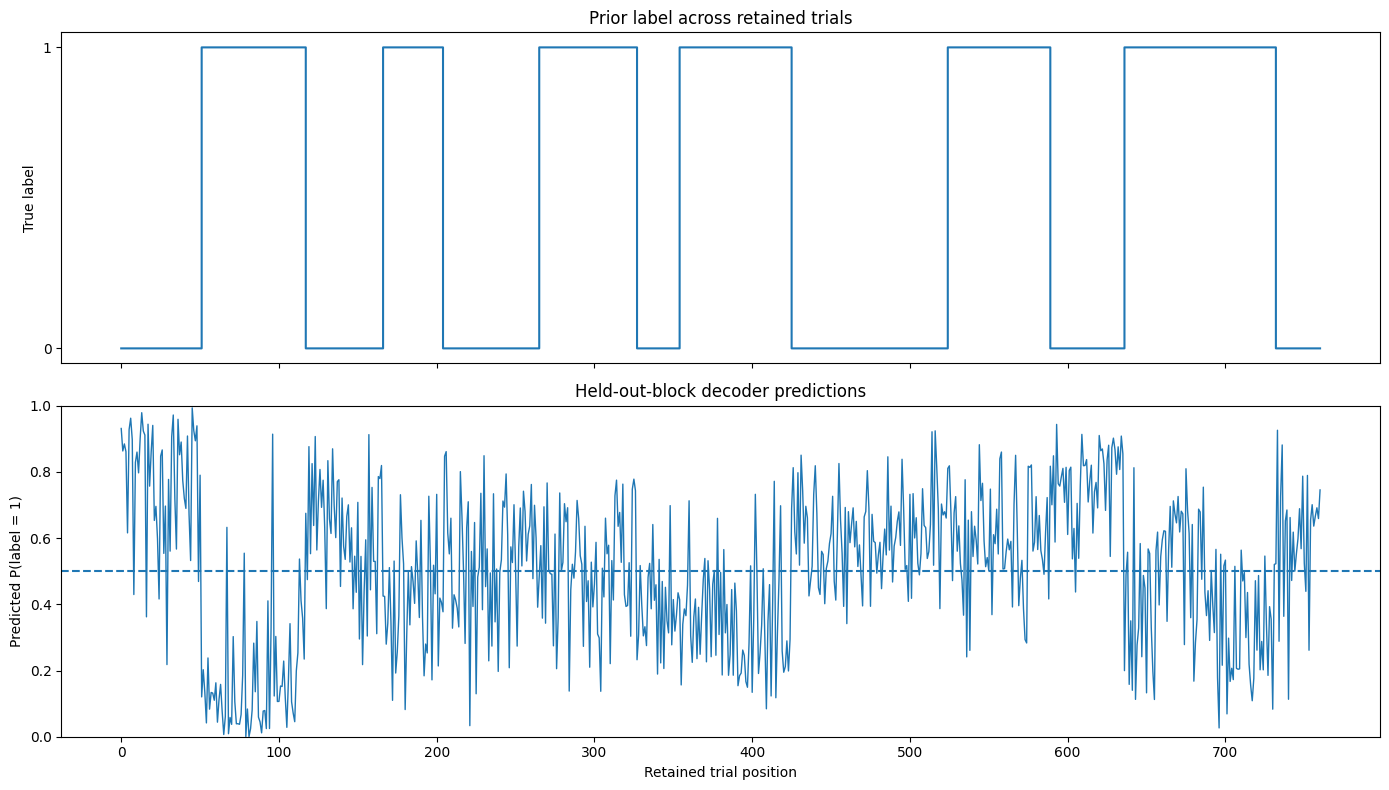

In [31]:

import matplotlib.pyplot as plt
import numpy as np

trial_positions = np.arange(len(y))

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# True prior label across trials
axes[0].step(
    trial_positions, y,
    where="post", linewidth=1.5
)
axes[0].set_ylabel("True label")
axes[0].set_yticks([0, 1])
axes[0].set_title("Prior label across retained trials")

# Out-of-fold probabilities
axes[1].plot(
    trial_positions, oof_probs,
    linewidth=1
)
axes[1].axhline(0.5, linestyle="--")
axes[1].set_ylabel("Predicted P(label = 1)")
axes[1].set_xlabel("Retained trial position")
axes[1].set_ylim(0, 1)
axes[1].set_title("Held-out-block decoder predictions")

plt.tight_layout()
plt.show()


In [32]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# Confirm that the rows of X, y, and tr refer to the same trials.
assert len(X) == len(y) == len(tr)

# Session position and block labels
diagnostic = pd.DataFrame({
    "trial_position": np.arange(len(y)),
    "prior_label": y,
    "block_index": tr["block_index"].to_numpy()
})

print("Correlation between trial position and prior label:")
print(spearmanr(
    diagnostic["trial_position"],
    diagnostic["prior_label"]
))

# Compare average neural activity across prior classes.
mean_activity = pd.DataFrame(X).groupby(y).mean()

print("\nMean activity by prior label (first 10 units):")
print(mean_activity.iloc[:, :10].round(3))

print("\nOverall mean and SD of neural features:")
print("Mean:", round(float(np.mean(X)), 4))
print("SD:", round(float(np.std(X)), 4))


Correlation between trial position and prior label:
SignificanceResult(statistic=np.float64(0.10752045504549618), pvalue=np.float64(0.002979728670355585))

Mean activity by prior label (first 10 units):
       0      1      2      3       4      5      6      7      8       9
0  0.967  0.587  0.744  0.926  39.879  0.270  5.204  5.154  4.006  12.994
1  0.663  0.188  0.595  1.166  39.211  0.214  6.003  6.440  4.447  14.339

Overall mean and SD of neural features:
Mean: 7.3415
SD: 10.8117


In [33]:

import numpy as np
import pandas as pd

# One row per trial, with the 50 neural features and block identity.
X_df = pd.DataFrame(
    X,
    columns=[f"unit_{i}" for i in range(X.shape[1])]
)
X_df["block_index"] = tr["block_index"].to_numpy()
X_df["prior_label"] = y

unit_cols = [c for c in X_df.columns if c.startswith("unit_")]

# Mean activity for each unit in each block.
block_means = X_df.groupby("block_index")[unit_cols].mean()

# Variance decomposition across trials:
# total variation = variation between block means + variation within blocks
X_values = X_df[unit_cols].to_numpy()
grand_mean = X_values.mean(axis=0)

between_ss = 0.0
within_ss = 0.0

for block_id, group in X_df.groupby("block_index"):
    values = group[unit_cols].to_numpy()
    block_mean = values.mean(axis=0)

    between_ss += len(values) * np.sum((block_mean - grand_mean) ** 2)
    within_ss += np.sum((values - block_mean) ** 2)

total_ss = np.sum((X_values - grand_mean) ** 2)

print("Total variation:", round(total_ss, 2))
print("Between-block variation:", round(between_ss, 2))
print("Within-block variation:", round(within_ss, 2))
print("Fraction of variation between blocks:", round(between_ss / total_ss, 3))

print("\nFirst 10 units: block means")
print(block_means.iloc[:, :10].round(3).to_string())


Total variation: 746435.27
Between-block variation: 315501.53
Within-block variation: 430933.75
Fraction of variation between blocks: 0.423

First 10 units: block means
             unit_0  unit_1  unit_2  unit_3  unit_4  unit_5  unit_6  unit_7  unit_8  unit_9
block_index                                                                                
1             4.157   1.882   2.235   1.745  42.137   0.039   4.706   6.549   2.451  12.412
2             3.167   0.576   2.197   3.727  46.818   0.288   6.530   6.667   3.227  16.955
3             2.796   1.184   1.796   2.776  46.653   0.184   4.673   5.041   3.184  15.204
4             1.447   0.000   2.421   3.053  44.816   0.000   4.763   6.842   4.289  15.316
5             0.033   0.262   1.115   1.049  44.705   0.000   4.557   5.656   3.689  14.689
6             0.000   0.113   0.000   0.210  40.323   0.097   4.774   8.097   3.661  15.032
7             0.000   0.222   0.000   0.148  40.778   0.815   5.370   5.148   4.630  13.926
8  

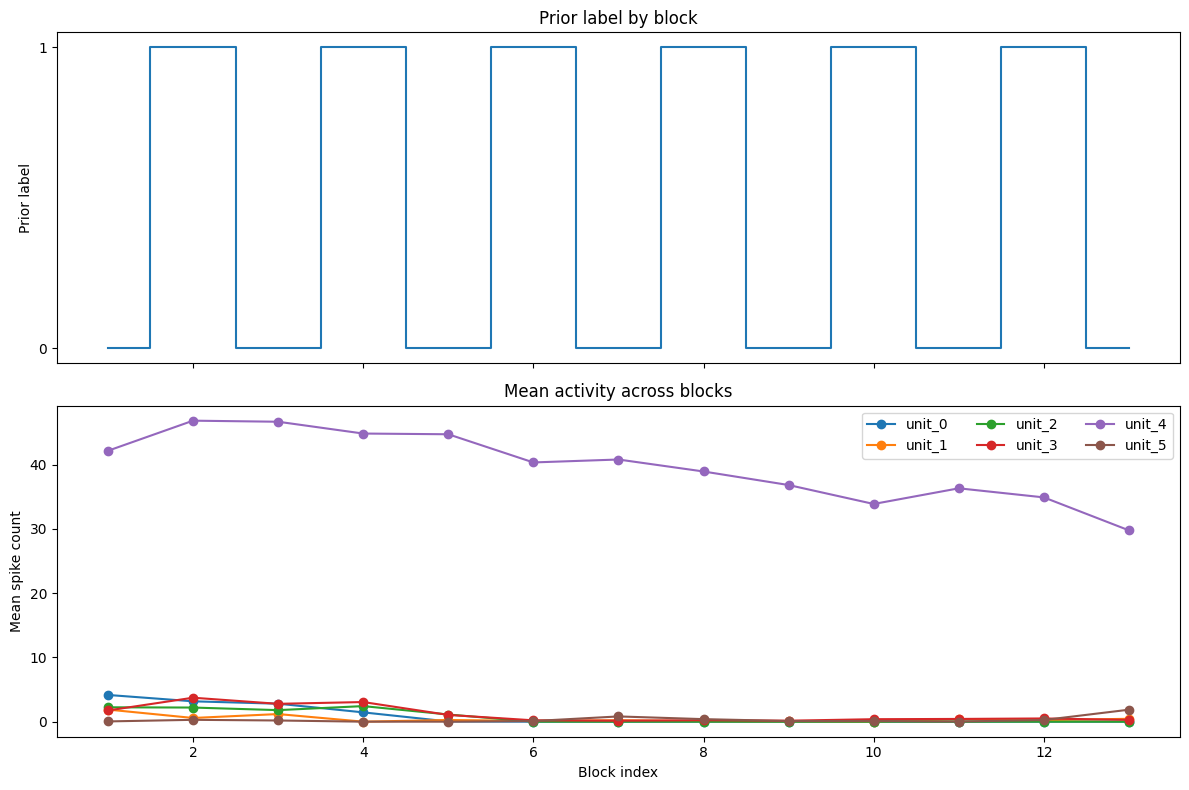

In [34]:

import matplotlib.pyplot as plt
import numpy as np

# Mean activity per block for the first 6 units
block_means = X_df.groupby("block_index")[unit_cols].mean()
block_labels = X_df.groupby("block_index")["prior_label"].first()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].step(
    block_labels.index,
    block_labels.values,
    where="mid"
)
axes[0].set_ylabel("Prior label")
axes[0].set_yticks([0, 1])
axes[0].set_title("Prior label by block")

for unit in unit_cols[:6]:
    axes[1].plot(
        block_means.index,
        block_means[unit],
        marker="o",
        label=unit
    )

axes[1].set_xlabel("Block index")
axes[1].set_ylabel("Mean spike count")
axes[1].set_title("Mean activity across blocks")
axes[1].legend(ncol=3)

plt.tight_layout()
plt.show()


In [35]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

positions = np.arange(len(X))
trend_results = []

for j in range(X.shape[1]):
    rho, p = spearmanr(positions, X[:, j])
    trend_results.append({
        "unit": j,
        "spearman_rho": rho,
        "p_value": p
    })

trend_df = pd.DataFrame(trend_results)
trend_df["abs_rho"] = trend_df["spearman_rho"].abs()

print("Units with the strongest monotonic time trends:")
print(
    trend_df.sort_values("abs_rho", ascending=False)
    .head(15)
    .round(4)
    .to_string(index=False)
)

print("\nNumber of units with |rho| > 0.3:",
      int((trend_df["abs_rho"] > 0.3).sum()))


Units with the strongest monotonic time trends:
 unit  spearman_rho  p_value  abs_rho
   40       -0.8316      0.0   0.8316
   18        0.7846      0.0   0.7846
   33        0.7661      0.0   0.7661
   20       -0.7484      0.0   0.7484
    0       -0.6847      0.0   0.6847
    2       -0.6471      0.0   0.6471
   48       -0.6233      0.0   0.6233
    4       -0.5969      0.0   0.5969
   29       -0.5685      0.0   0.5685
   23       -0.4301      0.0   0.4301
   47        0.4132      0.0   0.4132
    3       -0.3825      0.0   0.3825
   44       -0.3677      0.0   0.3677
   27        0.3454      0.0   0.3454
    8        0.3293      0.0   0.3293

Number of units with |rho| > 0.3: 16


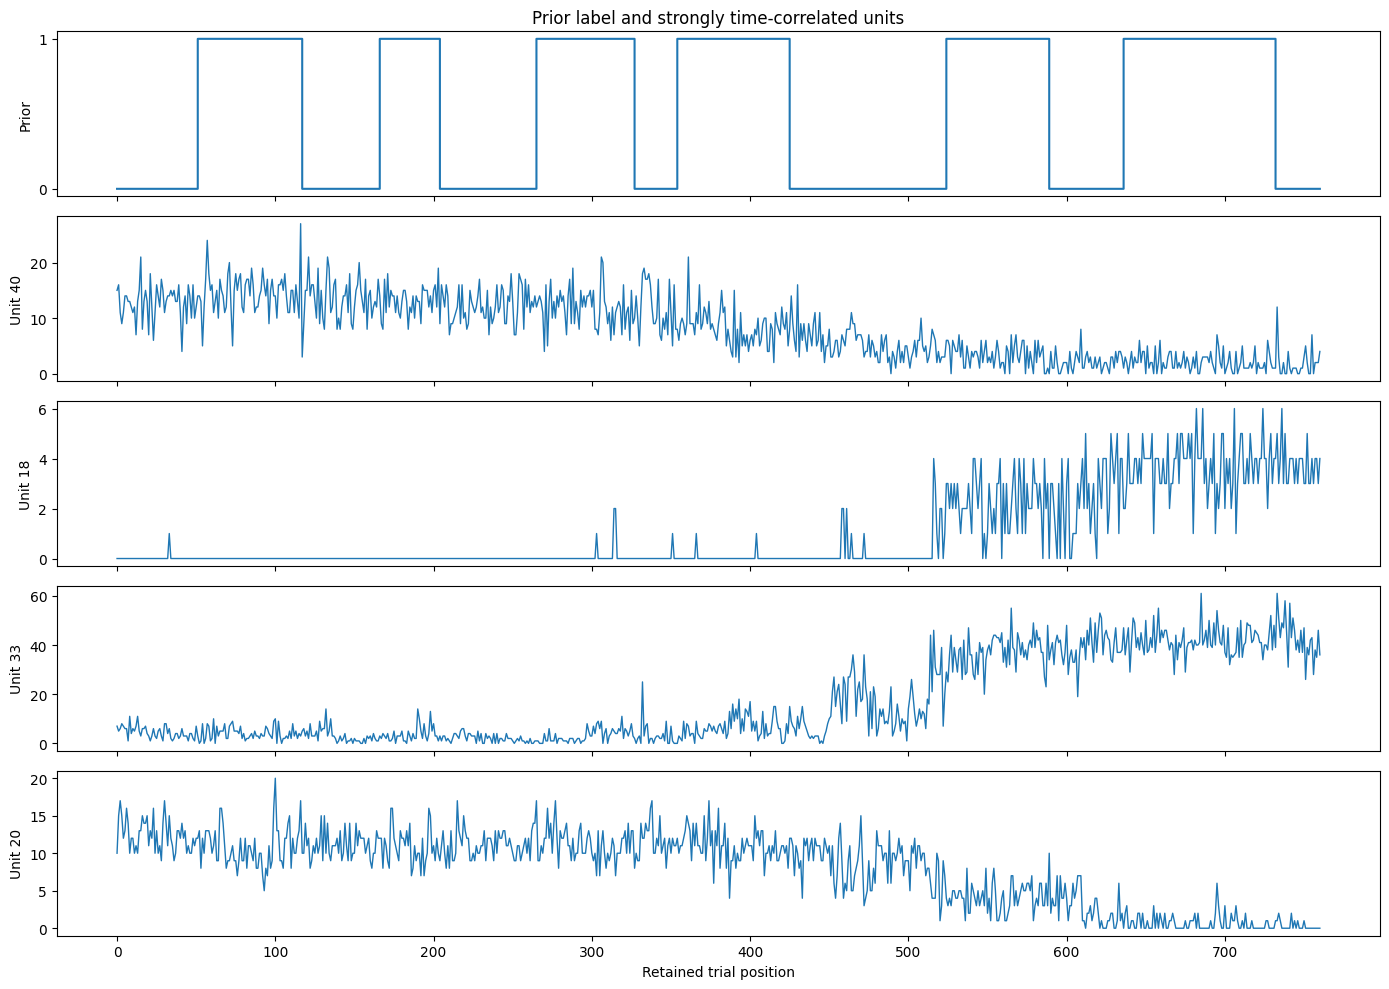

In [36]:

import matplotlib.pyplot as plt
import numpy as np

units_to_plot = [40, 18, 33, 20]
positions = np.arange(len(y))

fig, axes = plt.subplots(
    len(units_to_plot) + 1, 1,
    figsize=(14, 10),
    sharex=True
)

axes[0].step(positions, y, where="post")
axes[0].set_ylabel("Prior")
axes[0].set_yticks([0, 1])
axes[0].set_title("Prior label and strongly time-correlated units")

for ax, unit in zip(axes[1:], units_to_plot):
    ax.plot(positions, X[:, unit], linewidth=1)
    ax.set_ylabel(f"Unit {unit}")

axes[-1].set_xlabel("Retained trial position")
plt.tight_layout()
plt.show()


In [37]:

print("Available trial columns:")
print(tr.columns.tolist())


Available trial columns:
['start_time', 'stop_time', 'quiescence_period', 'gabor_stimulus_onset_time', 'auditory_cue_time', 'wheel_movement_onset_time', 'choice_registration_time', 'feedback_time', 'gabor_stimulus_offset_time', 'gabor_stimulus_contrast', 'gabor_stimulus_side', 'mouse_wheel_choice', 'is_mouse_rewarded', 'reward_volume_uL', 'probability_left', 'block_type', 'block_index']


In [38]:

import pandas as pd
import numpy as np

behavior_cols = [
    "gabor_stimulus_side",
    "gabor_stimulus_contrast",
    "mouse_wheel_choice",
    "is_mouse_rewarded",
    "reward_volume_uL",
    "probability_left",
    "block_type",
    "block_index"
]

for col in behavior_cols:
    print(f"\n--- {col} ---")
    print("Missing:", tr[col].isna().sum())
    print("Unique values:", tr[col].nunique(dropna=True))
    print(tr[col].value_counts(dropna=False).head(10).to_dict())

print("\nTiming columns:")
for col in [
    "start_time",
    "gabor_stimulus_onset_time",
    "wheel_movement_onset_time",
    "choice_registration_time",
    "feedback_time"
]:
    print(
        col,
        "| missing:", tr[col].isna().sum(),
        "| range:",
        (tr[col].min(), tr[col].max())
    )



--- gabor_stimulus_side ---
Missing: 0
Unique values: 2
{'left': 404, 'right': 357}

--- gabor_stimulus_contrast ---
Missing: 0
Unique values: 5
{12.5: 173, 100.0: 170, 6.25: 163, 25.0: 162, 0.0: 93}

--- mouse_wheel_choice ---
Missing: 0
Unique values: 3
{'clockwise': 426, 'counter_clockwise': 331, 'none': 4}

--- is_mouse_rewarded ---
Missing: 0
Unique values: 2
{True: 668, False: 93}

--- reward_volume_uL ---
Missing: 0
Unique values: 2
{1.5: 668, 0.0: 93}

--- probability_left ---
Missing: 0
Unique values: 2
{0.8: 398, 0.2: 363}

--- block_type ---
Missing: 0
Unique values: 2
{'left_block': 398, 'right_block': 363}

--- block_index ---
Missing: 0
Unique values: 13
{9: 99, 12: 96, 8: 71, 2: 66, 10: 65, 6: 62, 5: 61, 1: 51, 3: 49, 11: 47}

Timing columns:
start_time | missing: 0 | range: (634.8914045106349, 4418.245664584419)
gabor_stimulus_onset_time | missing: 0 | range: (635.6313971706356, 4418.816940784419)
wheel_movement_onset_time | missing: 56 | range: (635.6079904327062, 442

In [39]:

import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Preserve trial order.
beh = tr.copy().reset_index(drop=True)

# Encode the previous trial's stimulus, choice, and reward.
beh["prev_stim_left"] = (
    beh["gabor_stimulus_side"].shift(1) == "left"
).astype(int)

beh["prev_choice_cw"] = (
    beh["mouse_wheel_choice"].shift(1) == "clockwise"
).astype(int)

beh["prev_choice_ccw"] = (
    beh["mouse_wheel_choice"].shift(1) == "counter_clockwise"
).astype(int)

beh["prev_rewarded"] = (
    beh["is_mouse_rewarded"].shift(1).fillna(False).astype(int)
)

beh["prev_contrast"] = beh["gabor_stimulus_contrast"].shift(1)

# Drop the first row because it has no previous-trial history.
history_cols = [
    "prev_stim_left",
    "prev_choice_cw",
    "prev_choice_ccw",
    "prev_rewarded",
    "prev_contrast"
]

valid = beh["prev_contrast"].notna().to_numpy()
X_hist = beh.loc[valid, history_cols].to_numpy(dtype=float)
y_hist = y[valid]

print("History feature shape:", X_hist.shape)
print("Label counts:", dict(zip(*np.unique(y_hist, return_counts=True))))

# Forward validation: test on later trials.
tscv = TimeSeriesSplit(n_splits=5)
hist_probs = np.full(len(y_hist), np.nan)

for fold, (train_idx, test_idx) in enumerate(tscv.split(X_hist), start=1):
    if len(np.unique(y_hist[test_idx])) < 2:
        print(f"Fold {fold}: skipped (one test class)")
        continue

    history_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, max_iter=2000)
    )
    history_model.fit(X_hist[train_idx], y_hist[train_idx])
    hist_probs[test_idx] = history_model.predict_proba(
        X_hist[test_idx]
    )[:, 1]

scored = np.isfinite(hist_probs)

if scored.sum() and len(np.unique(y_hist[scored])) == 2:
    print(
        "Pooled history-only AUC:",
        round(roc_auc_score(y_hist[scored], hist_probs[scored]), 3)
    )
else:
    print("Pooled history-only AUC cannot be computed for these folds.")


History feature shape: (760, 5)
Label counts: {np.int64(0): np.int64(362), np.int64(1): np.int64(398)}
Pooled history-only AUC: 0.8


/tmp/ipykernel_1099/1950523293.py:27: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  beh["is_mouse_rewarded"].shift(1).fillna(False).astype(int)


In [40]:

import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Align every model to the same 760 trials.
# Row 0 has no previous-trial history, so exclude it from all models.
X_neural = np.asarray(X)[1:]
X_history = X_hist
y_compare = np.asarray(y)[1:]

assert len(X_neural) == len(X_history) == len(y_compare)

X_combined = np.column_stack([X_neural, X_history])

def make_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1",
            solver="liblinear",
            C=0.1,
            max_iter=2000
        )
    )

tscv = TimeSeriesSplit(n_splits=5)
results = []

for fold, (train_idx, test_idx) in enumerate(
    tscv.split(X_neural), start=1
):
    y_train = y_compare[train_idx]
    y_test = y_compare[test_idx]

    if len(np.unique(y_train)) < 2 or len(np.unique(y_test)) < 2:
        print(f"Fold {fold}: skipped because a set has only one class")
        continue

    row = {
        "fold": fold,
        "test_n": len(test_idx),
        "test_label_0": int(np.sum(y_test == 0)),
        "test_label_1": int(np.sum(y_test == 1))
    }

    for name, features in [
        ("history", X_history),
        ("neural", X_neural),
        ("combined", X_combined)
    ]:
        model = make_model()
        model.fit(features[train_idx], y_train)
        probs = model.predict_proba(features[test_idx])[:, 1]
        row[f"{name}_auc"] = roc_auc_score(y_test, probs)

    results.append(row)

results_df = pd.DataFrame(results)
print(results_df.round(3).to_string(index=False))

print("\nMean fold AUCs:")
print(results_df[
    ["history_auc", "neural_auc", "combined_auc"]
].mean().round(3))


 fold  test_n  test_label_0  test_label_1  history_auc  neural_auc  combined_auc
    1     126            88            38        0.793       0.633         0.779
    2     126            35            91        0.829       0.607         0.868
    3     126            84            42        0.824       0.521         0.838
    4     126            61            65        0.889       0.754         0.922
    5     126            30            96        0.854       0.731         0.907

Mean fold AUCs:
history_auc     0.838
neural_auc      0.649
combined_auc    0.863
dtype: float64


In [41]:

import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# All models use the same 760 trials.
positions = np.arange(len(y_compare)).reshape(-1, 1)

feature_sets = {
    "history": X_history,
    "history_time": np.column_stack([X_history, positions]),
    "history_neural": np.column_stack([X_history, X_neural]),
    "history_time_neural": np.column_stack([
        X_history, positions, X_neural
    ])
}

cv = TimeSeriesSplit(n_splits=5)
rows = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X_history), start=1
):
    y_train = y_compare[train_idx]
    y_test = y_compare[test_idx]

    if len(np.unique(y_train)) < 2 or len(np.unique(y_test)) < 2:
        continue

    row = {"fold": fold}

    for name, features in feature_sets.items():
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=0.1,
                max_iter=2000
            )
        )
        model.fit(features[train_idx], y_train)
        probs = model.predict_proba(features[test_idx])[:, 1]
        row[name] = roc_auc_score(y_test, probs)

    rows.append(row)

comparison = pd.DataFrame(rows)
print(comparison.round(3).to_string(index=False))

print("\nMean AUC:")
print(comparison.drop(columns="fold").mean().round(3))

print("\nNeural improvement after adding time:")
print(
    "Mean AUC difference:",
    round(
        (comparison["history_time_neural"]
         - comparison["history_time"]).mean(), 3
    )
)


 fold  history  history_time  history_neural  history_time_neural
    1    0.793         0.666           0.779                0.668
    2    0.829         0.831           0.868                0.868
    3    0.824         0.707           0.838                0.821
    4    0.889         0.889           0.922                0.922
    5    0.847         0.847           0.890                0.890

Mean AUC:
history                0.836
history_time           0.788
history_neural         0.859
history_time_neural    0.834
dtype: float64

Neural improvement after adding time:
Mean AUC difference: 0.046


In [42]:

from sklearn.metrics import log_loss
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

features = {
    "history_time": np.column_stack([X_history, positions]),
    "history_time_neural": np.column_stack([
        X_history, positions, X_neural
    ])
}

rows = []
cv = TimeSeriesSplit(n_splits=5)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X_history), start=1
):
    y_train = y_compare[train_idx]
    y_test = y_compare[test_idx]

    row = {"fold": fold}

    for name, feats in features.items():
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=0.1,
                max_iter=2000
            )
        )
        model.fit(feats[train_idx], y_train)
        probs = model.predict_proba(feats[test_idx])[:, 1]
        row[name + "_logloss"] = log_loss(y_test, probs)

    rows.append(row)

loss_df = pd.DataFrame(rows)
loss_df["improvement_with_neural"] = (
    loss_df["history_time_logloss"]
    - loss_df["history_time_neural_logloss"]
)

print(loss_df.round(4).to_string(index=False))
print("\nMean log-loss improvement from adding neural features:",
      round(loss_df["improvement_with_neural"].mean(), 4))


 fold  history_time_logloss  history_time_neural_logloss  improvement_with_neural
    1                1.1196                       1.1753                  -0.0557
    2                0.5673                       0.5697                  -0.0024
    3                0.5691                       0.5499                   0.0192
    4                0.4121                       0.3749                   0.0372
    5                0.4309                       0.4987                  -0.0678

Mean log-loss improvement from adding neural features: -0.0139


In [43]:

import pandas as pd
import numpy as np

# Summarize the results you've already calculated
summary = pd.DataFrame({
    "fold": [1, 2, 3, 4, 5],
    "AUC_history_time": [0.666, 0.831, 0.707, 0.889, 0.847],
    "AUC_history_time_neural": [0.668, 0.868, 0.821, 0.922, 0.890],
    "logloss_history_time": [1.1196, 0.5673, 0.5691, 0.4121, 0.4309],
    "logloss_history_time_neural": [1.1753, 0.5697, 0.5499, 0.3749, 0.4987],
})

summary["AUC_change"] = (
    summary["AUC_history_time_neural"]
    - summary["AUC_history_time"]
)

summary["logloss_change"] = (
    summary["logloss_history_time_neural"]
    - summary["logloss_history_time"]
)

print(summary.round(4).to_string(index=False))
print("\nMean AUC change:", round(summary["AUC_change"].mean(), 4))
print("Mean log-loss change:", round(summary["logloss_change"].mean(), 4))


 fold  AUC_history_time  AUC_history_time_neural  logloss_history_time  logloss_history_time_neural  AUC_change  logloss_change
    1             0.666                    0.668                1.1196                       1.1753       0.002          0.0557
    2             0.831                    0.868                0.5673                       0.5697       0.037          0.0024
    3             0.707                    0.821                0.5691                       0.5499       0.114         -0.0192
    4             0.889                    0.922                0.4121                       0.3749       0.033         -0.0372
    5             0.847                    0.890                0.4309                       0.4987       0.043          0.0678

Mean AUC change: 0.0458
Mean log-loss change: 0.0139


In [44]:

import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit

# These should align with the 760 rows used in model comparison.
# tr is the filtered trial dataframe used to construct X and y.
block_col = "block_index"

# The previous-trial features drop the first row, so align metadata too.
meta = tr.reset_index(drop=True).iloc[1:].reset_index(drop=True).copy()
labels = np.asarray(y_compare)

assert len(meta) == len(labels), (
    f"Metadata has {len(meta)} rows but labels have {len(labels)}"
)

meta["label"] = labels

cv = TimeSeriesSplit(n_splits=5)

rows = []
for fold, (train_idx, test_idx) in enumerate(cv.split(meta), start=1):
    train = meta.iloc[train_idx]
    test = meta.iloc[test_idx]

    rows.append({
        "fold": fold,
        "train_trials": len(train),
        "test_trials": len(test),
        "train_blocks": train[block_col].nunique(),
        "test_blocks": test[block_col].nunique(),
        "train_labels": train["label"].nunique(),
        "test_labels": test["label"].nunique(),
        "test_block_ids": sorted(test[block_col].unique().tolist()),
        "test_label_counts": test["label"].value_counts().to_dict()
    })

print(pd.DataFrame(rows).to_string(index=False))


 fold  train_trials  test_trials  train_blocks  test_blocks  train_labels  test_labels test_block_ids test_label_counts
    1           130          126             3            3             2            2      [3, 4, 5]    {0: 88, 1: 38}
    2           256          126             5            4             2            2   [5, 6, 7, 8]    {1: 91, 0: 35}
    3           382          126             8            2             2            2         [8, 9]    {0: 84, 1: 42}
    4           508          126             9            3             2            2    [9, 10, 11]    {1: 65, 0: 61}
    5           634          126            11            3             2            2   [11, 12, 13]    {1: 96, 0: 30}


In [45]:

# Inspect the relationship between block identity and prior-condition label.
block_summary = (
    meta.groupby(block_col)
    .agg(
        trials=("label", "size"),
        label_count=("label", "nunique"),
        prior_label=("label", "first")
    )
    .reset_index()
)

print(block_summary.to_string(index=False))

print("\nNumber of blocks:", len(block_summary))
print("Blocks containing both labels:",
      int((block_summary["label_count"] > 1).sum()))
print("Blocks containing only one label:",
      int((block_summary["label_count"] == 1).sum()))


 block_index  trials  label_count  prior_label
           1      50            1            0
           2      66            1            1
           3      49            1            0
           4      38            1            1
           5      61            1            0
           6      62            1            1
           7      27            1            0
           8      71            1            1
           9      99            1            0
          10      65            1            1
          11      47            1            0
          12      96            1            1
          13      29            1            0

Number of blocks: 13
Blocks containing both labels: 0
Blocks containing only one label: 13


In [46]:

from scipy.stats import spearmanr
import numpy as np
import pandas as pd

# X contains the neural features for the original 761 retained trials.
# tr contains the corresponding trial metadata.
X_array = np.asarray(X)
tr_check = tr.reset_index(drop=True).copy()

assert len(X_array) == len(tr_check)

within_block_results = []

for block_id, idx in tr_check.groupby("block_index").groups.items():
    idx = np.asarray(list(idx))
    if len(idx) < 10:
        continue

    # Position within this block
    within_pos = np.arange(len(idx))

    for unit in range(X_array.shape[1]):
        rho, p = spearmanr(within_pos, X_array[idx, unit])
        within_block_results.append({
            "block": block_id,
            "unit": unit,
            "rho": rho,
            "p": p,
            "n_trials": len(idx)
        })

within_df = pd.DataFrame(within_block_results)

# Descriptive summary; these p-values are not corrected for multiple testing.
print("Blocks analyzed:", within_df["block"].nunique())
print("Unit-block pairs analyzed:", len(within_df))
print("Median absolute within-block correlation:",
      round(within_df["rho"].abs().median(), 3))
print("Fraction with |rho| >= 0.3:",
      round((within_df["rho"].abs() >= 0.3).mean(), 3))
print("Fraction with |rho| >= 0.5:",
      round((within_df["rho"].abs() >= 0.5).mean(), 3))

print("\nMedian absolute correlation by block:")
print(
    within_df.groupby("block")["rho"]
    .apply(lambda s: s.abs().median())
    .round(3).to_string()
)


/tmp/ipykernel_1099/1847989748.py:23: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(within_pos, X_array[idx, unit])


Blocks analyzed: 13
Unit-block pairs analyzed: 650
Median absolute within-block correlation: 0.121
Fraction with |rho| >= 0.3: 0.112
Fraction with |rho| >= 0.5: 0.02

Median absolute correlation by block:
block
1     0.100
2     0.111
3     0.100
4     0.206
5     0.126
6     0.141
7     0.191
8     0.127
9     0.101
10    0.091
11    0.131
12    0.077
13    0.126


In [47]:

block_labels = (
    meta.groupby("block_index")["label"]
    .first()
    .value_counts()
    .sort_index()
)

print("Blocks per prior-condition label:")
print(block_labels.to_string())

print("\nBlock label sequence:")
print(
    meta.groupby("block_index")["label"]
    .first()
    .to_string()
)


Blocks per prior-condition label:
label
0    7
1    6

Block label sequence:
block_index
1     0
2     1
3     0
4     1
5     0
6     1
7     0
8     1
9     0
10    1
11    0
12    1
13    0


In [48]:

import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Align neural features, history features, labels, and block IDs.
Xn = np.asarray(X_neural)
Xh = np.asarray(X_history)
pos = np.asarray(positions).reshape(-1, 1)
labels = np.asarray(y_compare)
groups = meta["block_index"].to_numpy()

assert len(Xn) == len(Xh) == len(pos) == len(labels) == len(groups)

feature_sets = {
    "history": Xh,
    "history_time": np.column_stack([Xh, pos]),
    "history_time_neural": np.column_stack([Xh, pos, Xn])
}

logo = LeaveOneGroupOut()
results = []

for fold, (train_idx, test_idx) in enumerate(
    logo.split(Xh, labels, groups), start=1
):
    y_train = labels[train_idx]
    y_test = labels[test_idx]

    # A binary classifier cannot train on only one class.
    if len(np.unique(y_train)) < 2:
        continue

    row = {
        "held_out_block": groups[test_idx][0],
        "test_trials": len(test_idx),
        "true_label": int(y_test[0])
    }

    for name, feats in feature_sets.items():
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=0.1,
                max_iter=2000
            )
        )
        model.fit(feats[train_idx], y_train)
        pred = model.predict(feats[test_idx])

        row[name + "_accuracy"] = accuracy_score(y_test, pred)
        row[name + "_balanced_accuracy"] = (
            balanced_accuracy_score(y_test, pred)
        )

    results.append(row)

results_df = pd.DataFrame(results)
print(results_df.round(3).to_string(index=False))

print("\nMean block accuracy:")
print(results_df.filter(like="_accuracy").mean().round(3).to_string())


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

 held_out_block  test_trials  true_label  history_accuracy  history_balanced_accuracy  history_time_accuracy  history_time_balanced_accuracy  history_time_neural_accuracy  history_time_neural_balanced_accuracy
              1           50           0             0.760                      0.760                  0.760                           0.760                         0.520                                  0.520
              2           66           1             0.682                      0.682                  0.682                           0.682                         0.212                                  0.212
              3           49           0             0.714                      0.714                  0.714                           0.714                         0.673                                  0.673
              4           38           1             0.789                      0.789                  0.763                           0.763                    

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

In [49]:

final_summary = pd.DataFrame({
    "Analysis": [
        "Interleaved neural-only CV",
        "Forward neural-only CV",
        "Forward history-only CV",
        "Forward history + neural CV",
        "Held-out-block history-only accuracy",
        "Held-out-block history + time accuracy",
        "Held-out-block history + time + neural accuracy"
    ],
    "Result": [
        "AUC = 0.754",
        "Mean AUC = 0.649",
        "Mean AUC = 0.836",
        "Mean AUC = 0.859",
        "Accuracy = 0.754",
        "Accuracy = 0.747",
        "Accuracy = 0.681"
    ],
    "Interpretation": [
        "Potentially optimistic because trials are interleaved",
        "Limited forward predictive performance",
        "Behavior history is strongly predictive",
        "Small AUC increase; log loss worsened on average",
        "Baseline for unseen blocks",
        "Similar to history-only",
        "Adding neural features did not improve held-out-block accuracy"
    ]
})

print(final_summary.to_string(index=False))


                                       Analysis           Result                                                 Interpretation
                     Interleaved neural-only CV      AUC = 0.754          Potentially optimistic because trials are interleaved
                         Forward neural-only CV Mean AUC = 0.649                         Limited forward predictive performance
                        Forward history-only CV Mean AUC = 0.836                        Behavior history is strongly predictive
                    Forward history + neural CV Mean AUC = 0.859               Small AUC increase; log loss worsened on average
           Held-out-block history-only accuracy Accuracy = 0.754                                     Baseline for unseen blocks
         Held-out-block history + time accuracy Accuracy = 0.747                                        Similar to history-only
Held-out-block history + time + neural accuracy Accuracy = 0.681 Adding neural features did not improve 